4

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
data_a = pd.read_csv('data_A.csv')
data_b_train = pd.read_csv('data_B_train.csv')
data_b_val = pd.read_csv('data_B_val.csv')
print("Data A Head:\n", data_a.head())
print("\nData B Train Head:\n", data_b_train.head())

Data A Head:
           x         y
0  0.273923  0.930158
1 -0.460427 -0.293352
2 -0.918053  0.551072
3 -0.966945  0.139849
4  0.626540 -0.775260

Data B Train Head:
           x         y
0  0.050709  0.878013
1  0.459311 -0.217347
2  0.994420  0.067380
3 -0.460427  0.240713
4  0.082922  0.915824


In [2]:
def create_design_matrix(x, degree):
    X = np.column_stack([x**i for i in range(degree + 1)])
    return X

test_X = create_design_matrix(data_a['x'].head(), 2)
print("Design Matrix (Degree 2) Head:\n", test_X)

Design Matrix (Degree 2) Head:
 [[ 1.          0.27392337  0.07503402]
 [ 1.         -0.46042657  0.21199263]
 [ 1.         -0.91805295  0.84282122]
 [ 1.         -0.96694473  0.93498211]
 [ 1.          0.62654048  0.39255297]]


In [3]:
def fit_polynomial(X, y):
    theta = np.linalg.inv(X.T @ X) @ (X.T @ y)
    return theta

X_train_a = data_a['x'].values
y_train_a = data_a['y'].values
degrees = [1, 3, 9]
models_a = {}

for d in degrees:
    X_poly = create_design_matrix(X_train_a, d)
    models_a[d] = fit_polynomial(X_poly, y_train_a)
    print(f"Theta for degree {d} calculated.")

Theta for degree 1 calculated.
Theta for degree 3 calculated.
Theta for degree 9 calculated.


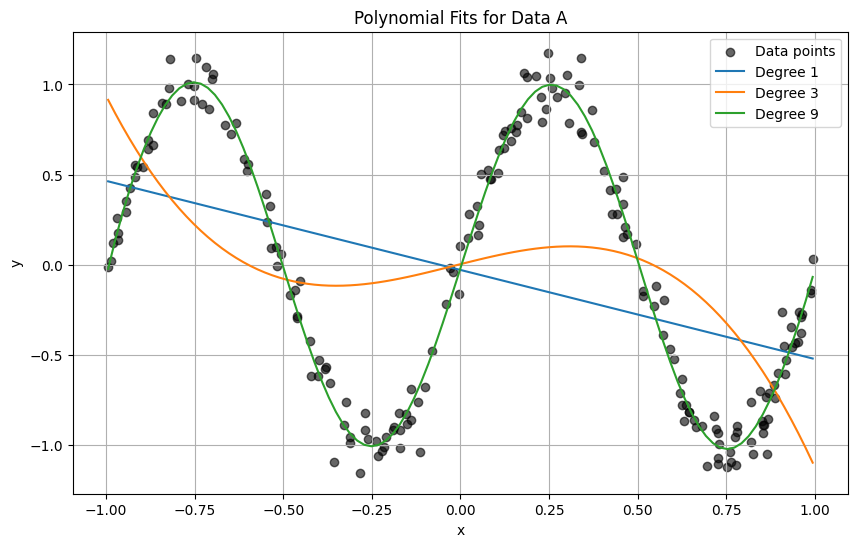

In [4]:
x_range = np.linspace(data_a['x'].min(), data_a['x'].max(), 100)

plt.figure(figsize=(10, 6))

plt.scatter(data_a['x'], data_a['y'], color='black', label='Data points', alpha=0.6)

for d in degrees:
    X_plot = create_design_matrix(x_range, d)
    y_plot = X_plot @ models_a[d]
    plt.plot(x_range, y_plot, label=f'Degree {d}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Fits for Data A')
plt.legend()
plt.grid(True)
plt.show()

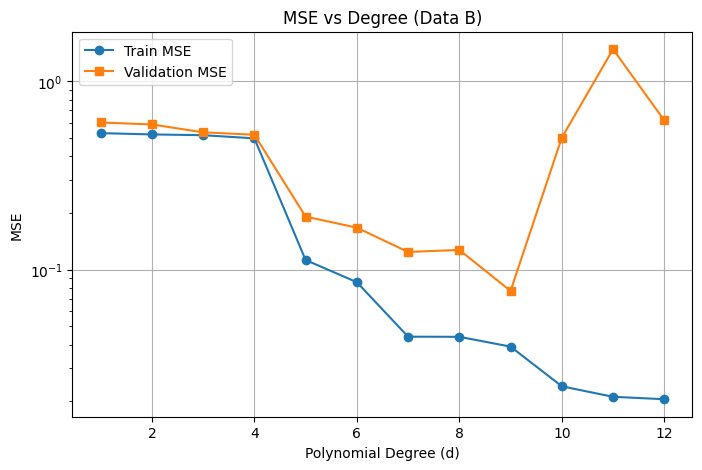

In [5]:
def compute_mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

x_train_b = data_b_train['x'].values
y_train_b = data_b_train['y'].values
x_val_b = data_b_val['x'].values
y_val_b = data_b_val['y'].values

train_mses = []
val_mses = []
degrees_range = range(1, 13)

for d in degrees_range:
    X_train = create_design_matrix(x_train_b, d)
    X_val = create_design_matrix(x_val_b, d)
    
    theta = fit_polynomial(X_train, y_train_b)
    
    y_train_pred = X_train @ theta
    y_val_pred = X_val @ theta
    
    train_mses.append(compute_mse(y_train_b, y_train_pred))
    val_mses.append(compute_mse(y_val_b, y_val_pred))

plt.figure(figsize=(8, 5))
plt.plot(degrees_range, train_mses, label='Train MSE', marker='o')
plt.plot(degrees_range, val_mses, label='Validation MSE', marker='s')
plt.xlabel('Polynomial Degree (d)')
plt.ylabel('MSE')
plt.yscale('log')
plt.title('MSE vs Degree (Data B)')
plt.legend()
plt.grid(True)
plt.show()

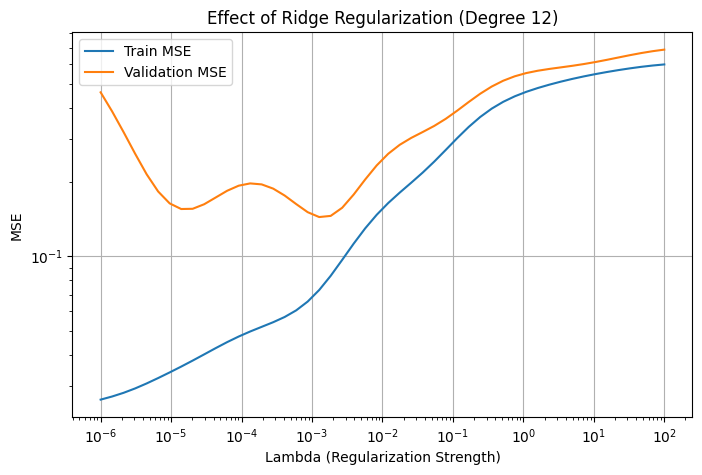

In [6]:
def fit_ridge(X, y, lambd):
    n_features = X.shape[1]
    identity = np.eye(n_features)
    theta = np.linalg.inv(X.T @ X + lambd * identity) @ (X.T @ y)
    return theta

fixed_degree = 12
lambdas = np.logspace(-6, 2, 50)

ridge_train_mses = []
ridge_val_mses = []

X_train_b_12 = create_design_matrix(x_train_b, fixed_degree)
X_val_b_12 = create_design_matrix(x_val_b, fixed_degree)

for l in lambdas:
    theta_l = fit_ridge(X_train_b_12, y_train_b, l)
    
    y_train_pred = X_train_b_12 @ theta_l
    y_val_pred = X_val_b_12 @ theta_l
    
    ridge_train_mses.append(compute_mse(y_train_b, y_train_pred))
    ridge_val_mses.append(compute_mse(y_val_b, y_val_pred))

plt.figure(figsize=(8, 5))
plt.plot(lambdas, ridge_train_mses, label='Train MSE')
plt.plot(lambdas, ridge_val_mses, label='Validation MSE')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Lambda (Regularization Strength)')
plt.ylabel('MSE')
plt.title('Effect of Ridge Regularization (Degree 12)')
plt.legend()
plt.grid(True)
plt.show()